# 3. BBMR — ROBUSTNESS BATTERY & VALIDATION GATE

Full 7-phase audit:
1. OOS validation (Capital + ATR sizing)
2. Walk-forward (3Y IS / 1Y OOS)
3. Block Monte Carlo (10,000 circular resamples)
4. Monkey test (2,000 synthetic filter-eligible portfolios)
5. Stress (2× costs, best-years removed, crisis regimes)
6. Edge decay (rolling 40-trade PF)
7. Full validation gate (ATR official + Capital for transparency)

In [3]:
VARIANT = "v1_us500"

In [4]:
import os, sys, importlib
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

def find_upwards(name, start=None, must_be_dir=True):
    here = (start or Path.cwd()).resolve()
    for base in (here, *here.parents):
        target = base / name
        if target.is_dir() if must_be_dir else target.exists(): return base
    raise FileNotFoundError(f"Could not find '{name}' from {here}")

EDGE_DIR    = find_upwards('variants')
utils_path  = str(find_upwards('utils') / 'utils')
engine_path = str(EDGE_DIR); engine_dir = str(EDGE_DIR / 'bbmr_engine')
for p in (utils_path, engine_path, engine_dir):
    if p not in sys.path: sys.path.insert(0, p)

from utils import compute_metrics, plot_equity_curve
from metrics import sharpe_ratio, max_drawdown
from robustness import monte_carlo_block, monkey_test, grid_search, plateau_check, plot_grid, plot_monkey
from edge_decay import rolling_pf, plot_rolling_pf, pf_by_year, edge_decay_summary
from validation_gate import run_validation
import bbmr_engine as eng
import variant_config
from variant_config import load_variant, save_json

importlib.reload(eng)
variant_config.EDGE_DIR = EDGE_DIR

cfg         = load_variant(VARIANT)
eng.set_engine_defaults(**cfg.get("engine_defaults", {}))
RUN_DIR     = cfg["run_dir"]
TICKER      = cfg["instrument"]["ticker"]
DATA_START  = cfg["instrument"]["start"]
OOS_START   = cfg["oos_start_ts"]
BB_LEN          = cfg["params"]["bb_len"]
BB_STD          = cfg["params"]["bb_std"]
ADX_THR         = cfg["params"]["adx_thr"]
SMA_LEN         = cfg["params"]["sma_len"]
REJECTION_RATIO = cfg["params"]["rejection_ratio"]
MAX_BARS        = cfg["params"]["max_bars"]
ATR_STOP_MULT   = cfg["params"]["atr_stop_mult"]
SLIP_BPS        = cfg["params"]["slip_bps_per_side"]
ADX_VALUES      = cfg["grid"]["adx_values"]
BB_STD_VALUES   = cfg["grid"]["bb_std_values"]

print(f"Variant: {cfg['id']} | {TICKER} | BB({BB_LEN},{BB_STD}) ADX<{ADX_THR} SMA({SMA_LEN})")

def _kw(**over):
    kw = dict(bb_len=BB_LEN, bb_std=BB_STD, adx_thr=ADX_THR, sma_len=SMA_LEN,
              rejection_ratio=REJECTION_RATIO, max_bars=MAX_BARS,
              atr_stop_mult=ATR_STOP_MULT, slip_bps_per_side=SLIP_BPS)
    kw.update(over); return kw

Variant: BBMR.us500.m30 | us500 | BB(20,2.0) ADX<25.0 SMA(200)


## 2. OOS PERFORMANCE & COMPARISON (Capital + ATR)

OOS COMPARISON (2018-09-24 → 2026-10-16)


,Metric,IS (Capital),OOS (Capital),IS (ATR),OOS (ATR)
0,Trades,27,29,27,29
1,Win Rate,74.1%,58.6%,74.1%,58.6%
2,Profit Factor,1.685,1.041,1.850,0.935
3,Sharpe,0.49,0.12,0.58,0.02
4,Max DD,-4.63%,-13.77%,-2.68%,-6.37%


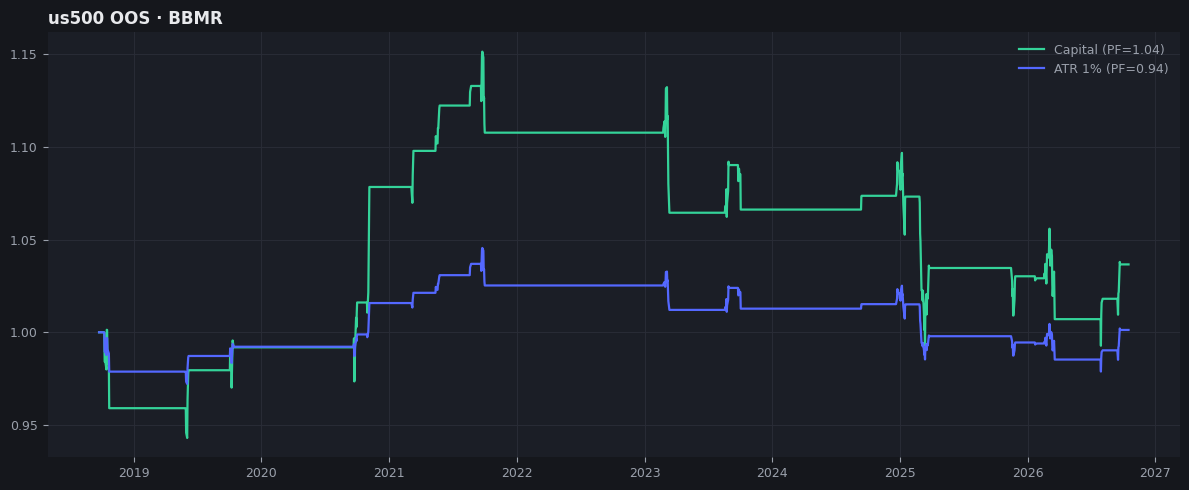

In [5]:
df_raw = eng.load_data(TICKER, start=DATA_START)
common_start = eng.prepare(df_raw, sma_len=SMA_LEN, bb_len=BB_LEN, bb_std=max(BB_STD_VALUES)).index[0]
df = eng.prepare(df_raw, sma_len=SMA_LEN, bb_len=BB_LEN, bb_std=BB_STD)
df = df[df.index >= common_start]
n_is = int((df.index < OOS_START).sum())
df_is, df_oos = df.iloc[:n_is].copy(), df.iloc[n_is:].copy()
oos_start = df_oos.index[0]

trades_all = eng.run_bbmr_backtest(df, **_kw())
trades_is  = eng.run_bbmr_backtest(df_is, **_kw())
trades_oos = eng.run_bbmr_backtest(df_oos, **_kw())

trades_atr     = trades_all.assign(pnl=trades_all['pnl_atr'], win=trades_all['pnl_atr'] > 0)
trades_is_atr  = trades_is.assign(pnl=trades_is['pnl_atr'],  win=trades_is['pnl_atr'] > 0)
trades_oos_atr = trades_oos.assign(pnl=trades_oos['pnl_atr'], win=trades_oos['pnl_atr'] > 0)

ret_cap_is  = eng.daily_returns(df_is, trades_is, sizing="capital")
ret_cap_oos = eng.daily_returns(df_oos, trades_oos, sizing="capital")
ret_atr_is  = eng.daily_returns(df_is, trades_is, sizing="atr")
ret_atr_oos = eng.daily_returns(df_oos, trades_oos, sizing="atr")

eq_cap_oos = (1 + ret_cap_oos).cumprod()
eq_atr_oos = (1 + ret_atr_oos).cumprod()

oos_comparison = pd.DataFrame([
    {"Metric":"Trades","IS (Capital)":len(trades_is),"OOS (Capital)":len(trades_oos),
     "IS (ATR)":len(trades_is_atr),"OOS (ATR)":len(trades_oos_atr)},
    {"Metric":"Win Rate","IS (Capital)":f"{trades_is['win'].mean()*100:.1f}%",
     "OOS (Capital)":f"{trades_oos['win'].mean()*100:.1f}%",
     "IS (ATR)":f"{trades_is_atr['win'].mean()*100:.1f}%",
     "OOS (ATR)":f"{trades_oos_atr['win'].mean()*100:.1f}%"},
    {"Metric":"Profit Factor","IS (Capital)":f"{compute_metrics(trades_is,1.0)['profit_factor']:.3f}",
     "OOS (Capital)":f"{compute_metrics(trades_oos,1.0)['profit_factor']:.3f}",
     "IS (ATR)":f"{compute_metrics(trades_is_atr,1.0)['profit_factor']:.3f}",
     "OOS (ATR)":f"{compute_metrics(trades_oos_atr,1.0)['profit_factor']:.3f}"},
    {"Metric":"Sharpe","IS (Capital)":f"{sharpe_ratio(ret_cap_is):.2f}",
     "OOS (Capital)":f"{sharpe_ratio(ret_cap_oos):.2f}",
     "IS (ATR)":f"{sharpe_ratio(ret_atr_is):.2f}","OOS (ATR)":f"{sharpe_ratio(ret_atr_oos):.2f}"},
    {"Metric":"Max DD",
     "IS (Capital)":f"{max_drawdown((1+ret_cap_is).cumprod())*100:.2f}%",
     "OOS (Capital)":f"{max_drawdown(eq_cap_oos)*100:.2f}%",
     "IS (ATR)":f"{max_drawdown((1+ret_atr_is).cumprod())*100:.2f}%",
     "OOS (ATR)":f"{max_drawdown(eq_atr_oos)*100:.2f}%"},
])

print("=" * 80); print(f"OOS COMPARISON ({oos_start:%Y-%m-%d} → {df_oos.index[-1]:%Y-%m-%d})"); print("=" * 80)
display(oos_comparison)

fig, ax = plt.subplots(figsize=(12, 5), facecolor='#15171c')
ax.set_facecolor('#1b1e26'); ax.grid(True, color='#2a2d37', linewidth=0.8, alpha=0.9)
for s in ax.spines.values(): s.set_visible(False)
ax.tick_params(colors='#9aa0ab', labelsize=9)
ax.plot(df_oos.index, eq_cap_oos, color='#34d399', lw=1.6,
        label=f"Capital (PF={compute_metrics(trades_oos,1.0)['profit_factor']:.2f})")
ax.plot(df_oos.index, eq_atr_oos, color='#5468ff', lw=1.6,
        label=f"ATR 1% (PF={compute_metrics(trades_oos_atr,1.0)['profit_factor']:.2f})")
ax.set_title(f'{TICKER} OOS · BBMR', color='#e8e9ec', fontweight='bold', fontsize=12, loc='left')
ax.legend(frameon=False, labelcolor='#9aa0ab', fontsize=9)
plt.tight_layout(); plt.show()

## 3. WALK-FORWARD ANALYSIS

WALK-FORWARD (9 windows)
WFE: 0.173 (>= 0.50)
Positive OOS years: 55.6% (5/9) (>= 60%)
Worst OOS DD: -7.48% (> -20%)
Verdict: FAILED


,year,ret_is_anual,ret_oos,n_oos,pf_oos,mdd_oos
0,2017,0.024528,0.025332,4,inf,-0.005587
1,2018,0.051517,-0.061932,4,0.170075,-0.061932
2,2019,0.007514,0.034210,2,inf,-0.019724
3,2020,-0.001755,0.087144,2,inf,-0.023294
4,2021,0.018234,0.027147,5,2.233532,-0.037938
5,2022,0.051619,0.000000,0,NaN,0.000000
6,2023,0.038886,-0.037426,3,0.395914,-0.061770
7,2024,-0.003765,0.012288,3,2.734403,-0.011369
8,2025,-0.008533,-0.055945,7,0.463949,-0.074831


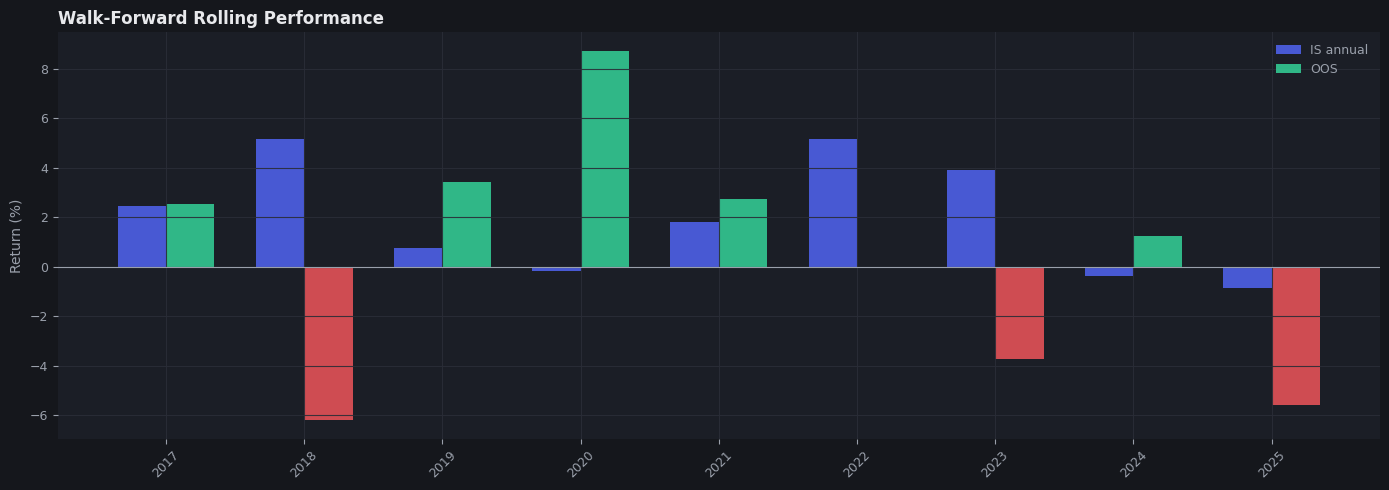

In [6]:
wf_df = eng.walk_forward_fixed(df, rules=_kw(), is_years=3)
mean_is  = wf_df['ret_is_anual'].mean(); mean_oos = wf_df['ret_oos'].mean()
efficiency = mean_oos/mean_is if mean_is > 0 else np.nan
pct_pos  = (wf_df['ret_oos'] > 0).mean()
worst_mdd = wf_df['mdd_oos'].min()
wf_pass = (efficiency >= 0.5) and (pct_pos >= 0.6) and (worst_mdd > -0.20)

print("=" * 70); print(f"WALK-FORWARD ({len(wf_df)} windows)"); print("=" * 70)
print(f"WFE: {efficiency:.3f} (>= 0.50)")
print(f"Positive OOS years: {pct_pos*100:.1f}% ({int(pct_pos*len(wf_df))}/{len(wf_df)}) (>= 60%)")
print(f"Worst OOS DD: {worst_mdd*100:.2f}% (> -20%)")
print(f"Verdict: {'PASSED' if wf_pass else 'FAILED'}")
display(wf_df)

fig, ax = plt.subplots(figsize=(14, 5), facecolor='#15171c')
ax.set_facecolor('#1b1e26'); ax.grid(True, color='#2a2d37', linewidth=0.8, alpha=0.9)
for s in ax.spines.values(): s.set_visible(False)
ax.tick_params(colors='#9aa0ab', labelsize=9)
x = np.arange(len(wf_df)); w = 0.35
ax.bar(x-w/2, wf_df['ret_is_anual']*100, w, label='IS annual', color='#5468ff', alpha=0.8)
ax.bar(x+w/2, wf_df['ret_oos']*100, w, label='OOS',
       color=['#34d399' if r>0 else '#f0555a' for r in wf_df['ret_oos']], alpha=0.85)
ax.axhline(0, color='#9aa0ab', lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(wf_df['year'], rotation=45, color='#9aa0ab')
ax.set_title('Walk-Forward Rolling Performance', color='#e8e9ec', fontweight='bold', fontsize=12, loc='left')
ax.set_ylabel('Return (%)', color='#9aa0ab'); ax.legend(frameon=False, labelcolor='#9aa0ab', fontsize=9)
plt.tight_layout(); plt.show()

## 4. BLOCK MONTE CARLO (10,000 SIMULATIONS)

BLOCK MONTE CARLO


,Metric,Capital,ATR
0,Median Return,7.5%,3.8%
1,5th Pct Return,-17.3%,-7.1%
2,Median MDD,-13.73%,-5.86%
3,Worst 5% MDD,-25.39%,-11.32%
4,Worst MDD,-45.34%,-23.81%
5,P(ruin),0.00%,0.00%
6,P(positive),66.95%,70.96%


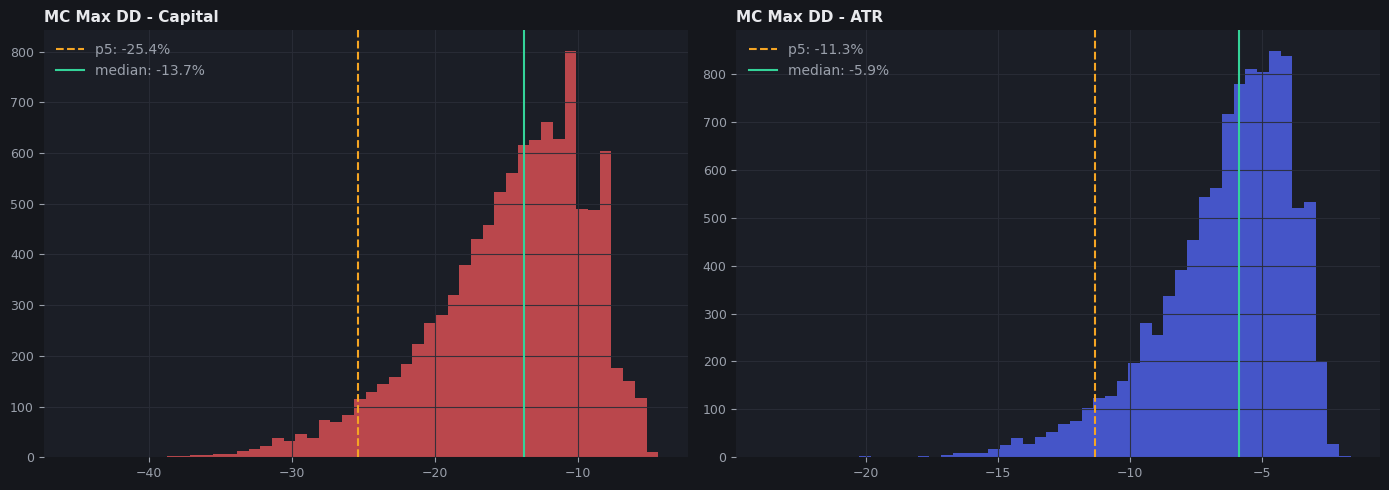

In [7]:
paths_cap = eng.trade_mtm_paths(df, trades_all, sizing="capital")
paths_atr = eng.trade_mtm_paths(df, trades_all, sizing="atr")

mc_cap = monte_carlo_block(trades_all, n_sim=10000, block=5, mode="compound", seed=42, mtm_paths=paths_cap)
mc_atr = monte_carlo_block(trades_atr, n_sim=10000, block=5, mode="compound", seed=42, mtm_paths=paths_atr)

mc_summary = pd.DataFrame([
    {"Metric":"Median Return","Capital":f"{mc_cap['ret_p50']*100:.1f}%","ATR":f"{mc_atr['ret_p50']*100:.1f}%"},
    {"Metric":"5th Pct Return","Capital":f"{mc_cap['ret_p5']*100:.1f}%","ATR":f"{mc_atr['ret_p5']*100:.1f}%"},
    {"Metric":"Median MDD","Capital":f"{mc_cap['mdd_p50']*100:.2f}%","ATR":f"{mc_atr['mdd_p50']*100:.2f}%"},
    {"Metric":"Worst 5% MDD","Capital":f"{mc_cap['mdd_p5']*100:.2f}%","ATR":f"{mc_atr['mdd_p5']*100:.2f}%"},
    {"Metric":"Worst MDD","Capital":f"{mc_cap['mdd_worst']*100:.2f}%","ATR":f"{mc_atr['mdd_worst']*100:.2f}%"},
    {"Metric":"P(ruin)","Capital":f"{mc_cap['prob_ruin']*100:.2f}%","ATR":f"{mc_atr['prob_ruin']*100:.2f}%"},
    {"Metric":"P(positive)","Capital":f"{mc_cap['prob_positive']*100:.2f}%","ATR":f"{mc_atr['prob_positive']*100:.2f}%"},
])
print("=" * 70); print("BLOCK MONTE CARLO"); print("=" * 70); display(mc_summary)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), facecolor='#15171c')
for ax in (ax1, ax2):
    ax.set_facecolor('#1b1e26'); ax.grid(True, color='#2a2d37', linewidth=0.8, alpha=0.9)
    for s in ax.spines.values(): s.set_visible(False)
    ax.tick_params(colors='#9aa0ab', labelsize=9)
ax1.hist(mc_cap['mdds']*100, bins=50, color='#f0555a', alpha=0.75)
ax1.axvline(mc_cap['mdd_p5']*100, color='#f5a524', ls='--', lw=1.5, label=f"p5: {mc_cap['mdd_p5']*100:.1f}%")
ax1.axvline(mc_cap['mdd_p50']*100, color='#34d399', lw=1.5, label=f"median: {mc_cap['mdd_p50']*100:.1f}%")
ax1.set_title('MC Max DD - Capital', color='#e8e9ec', fontweight='bold', fontsize=11, loc='left')
ax1.legend(frameon=False, labelcolor='#9aa0ab')
ax2.hist(mc_atr['mdds']*100, bins=50, color='#5468ff', alpha=0.75)
ax2.axvline(mc_atr['mdd_p5']*100, color='#f5a524', ls='--', lw=1.5, label=f"p5: {mc_atr['mdd_p5']*100:.1f}%")
ax2.axvline(mc_atr['mdd_p50']*100, color='#34d399', lw=1.5, label=f"median: {mc_atr['mdd_p50']*100:.1f}%")
ax2.set_title('MC Max DD - ATR', color='#e8e9ec', fontweight='bold', fontsize=11, loc='left')
ax2.legend(frameon=False, labelcolor='#9aa0ab')
plt.tight_layout(); plt.show()

## 5. MONKEY TEST

MONKEY TEST
Strategy realized PF: 1.222
Monkey median PF    : 1.085
% Monkeys beaten    : 62.85% (>= 95.0%)
Verdict: FAILED


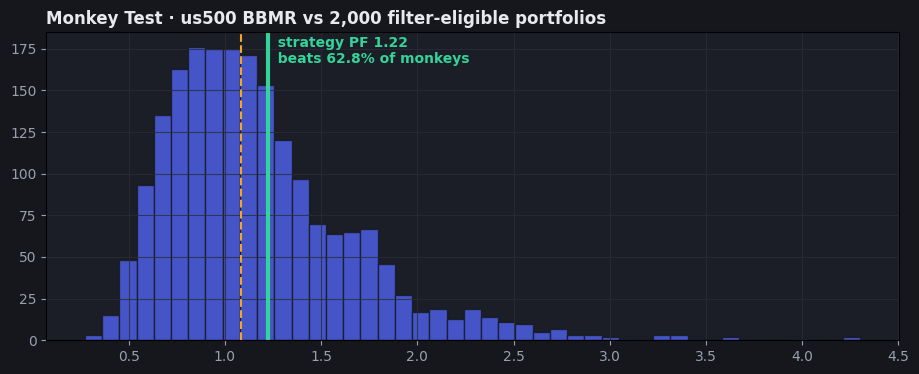

In [8]:
eligible = ((df['close'] > df['sma']) & (df['adx'] < ADX_THR)).shift(1)

mk = monkey_test(
    df=df, trades_df=trades_all, eligible=eligible,
    n_sim=2000, entry_col="open", exit_col="open",
    cost_pct_per_side=SLIP_BPS / 100.0, seed=42,
)
print("=" * 70); print("MONKEY TEST"); print("=" * 70)
print(f"Strategy realized PF: {mk['pf_real']:.3f}")
print(f"Monkey median PF    : {mk['pf_monkey_median']:.3f}")
print(f"% Monkeys beaten    : {mk['pct_pf']*100:.2f}% (>= 95.0%)")
print(f"Verdict: {'PASSED' if mk['pct_pf'] >= 0.95 else 'FAILED'}")
plot_monkey(mk, title=f"Monkey Test · {TICKER} BBMR vs 2,000 filter-eligible portfolios")

## 6. STRESS TESTING

In [9]:
print("=" * 70); print("STRESS TESTING"); print("=" * 70)

trades_x2 = eng.run_bbmr_backtest(df, **_kw(slip_bps_per_side=2*SLIP_BPS))
m_x2 = compute_metrics(trades_x2, 1.0, 0.0)

trades_all['year'] = pd.to_datetime(trades_all['entry_time']).dt.year
ann_pnl = trades_all.groupby('year')['pnl'].sum()
top2 = ann_pnl.sort_values(ascending=False).head(2).index.tolist()
trades_ex2 = trades_all[~trades_all['year'].isin(top2)]
m_ex2 = compute_metrics(trades_ex2, 1.0, 0.0)

regimes = {"Dot-Com (2000-2002)":(2000,2002), "GFC (2008)":(2008,2008), "Rate-Hike (2022)":(2022,2022)}

stress_rows = [
    {"Scenario":"Baseline", "Trades":len(trades_all),
     "Win Rate":f"{trades_all['win'].mean()*100:.1f}%",
     "Profit Factor":f"{compute_metrics(trades_all,1.0)['profit_factor']:.3f}",
     "Expectancy":f"{trades_all['pnl'].mean():.2f}%"},
    {"Scenario":"Costs ×2", "Trades":len(trades_x2),
     "Win Rate":f"{trades_x2['win'].mean()*100:.1f}%",
     "Profit Factor":f"{m_x2['profit_factor']:.3f}",
     "Expectancy":f"{m_x2['expectancy']:.2f}%"},
    {"Scenario":f"Excl. best 2 years ({top2[0]},{top2[1]})", "Trades":len(trades_ex2),
     "Win Rate":f"{trades_ex2['win'].mean()*100:.1f}%",
     "Profit Factor":f"{m_ex2['profit_factor']:.3f}",
     "Expectancy":f"{m_ex2['expectancy']:.2f}%"},
]
for name, (s,e) in regimes.items():
    tr = trades_all[(trades_all['year'] >= s) & (trades_all['year'] <= e)]
    if len(tr) > 0:
        mr = compute_metrics(tr, 1.0, 0.0)
        stress_rows.append({"Scenario":name, "Trades":len(tr),
                            "Win Rate":f"{tr['win'].mean()*100:.1f}%",
                            "Profit Factor":f"{mr['profit_factor']:.3f}",
                            "Expectancy":f"{mr['expectancy']:.2f}%"})
    else:
        stress_rows.append({"Scenario":name, "Trades":0, "Win Rate":"N/A",
                            "Profit Factor":"N/A", "Expectancy":"N/A"})

display(pd.DataFrame(stress_rows))

STRESS TESTING


,Scenario,Trades,Win Rate,Profit Factor,Expectancy
0,Baseline,56,66.1%,1.222,0.16%
1,Costs ×2,56,64.3%,0.989,-0.01%
2,"Excl. best 2 years (2020,2016)",48,62.5%,0.856,-0.12%
3,Dot-Com (2000-2002),0,N/A,N/A,N/A
4,GFC (2008),0,N/A,N/A,N/A
5,Rate-Hike (2022),0,N/A,N/A,N/A


## 7. EDGE DECAY

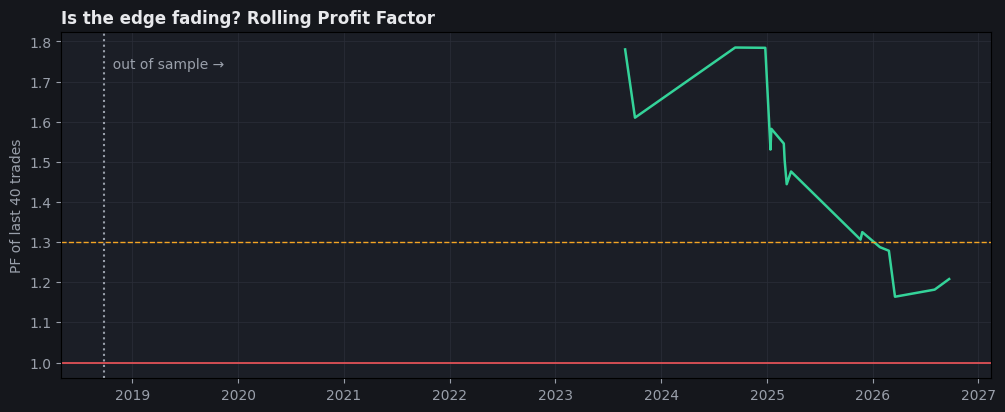

ANNUAL PERFORMANCE BREAKDOWN


,n,pf,expectancy,win_rate,total_pnl
year,,,,,
2013,1,inf,0.131,1.000,0.131
2014,7,0.377,-0.669,0.429,-4.680
2015,7,21.168,0.826,0.857,5.785
2016,6,55.544,1.028,0.833,6.168
2017,4,inf,0.628,1.000,2.512
2018,4,0.170,-1.570,0.250,-6.279
2019,2,inf,1.697,1.000,3.394
2020,2,inf,4.283,1.000,8.565
2021,5,2.234,0.548,0.800,2.742


Historical PF: 2.036 | Recent PF: 0.477
Expectancy ratio: -1.607 | Warning: True


In [10]:
roll = rolling_pf(trades_all, window=40, cap=8.0, date_col="exit_time")
plot_rolling_pf(roll, oos_start=oos_start, window=40)
by_year = pf_by_year(trades_all, date_col="exit_time")
print("ANNUAL PERFORMANCE BREAKDOWN"); display(by_year.round(3))

decay = edge_decay_summary(trades_all, last_n=3, date_col="exit_time")
print(f"Historical PF: {decay['historical']['pf']:.3f} | Recent PF: {decay['recent']['pf']:.3f}")
print(f"Expectancy ratio: {decay['expectancy_ratio']:.3f} | Warning: {decay['warning']}")

## 8. FULL VALIDATION GATE (ATR official + Capital for transparency)

In [11]:
is_dfs = {}
for s in BB_STD_VALUES:
    d_prep = eng.prepare(df_raw, sma_len=SMA_LEN, bb_len=BB_LEN, bb_std=s)
    is_dfs[s] = d_prep[d_prep.index < oos_start]

def evaluate_gate(adx, bb_std):
    d = is_dfs[bb_std]
    t = eng.run_bbmr_backtest(d, **_kw(bb_std=bb_std, adx_thr=adx))
    if len(t) == 0: return (0.0, 0)
    p = t['pnl'].values; g, l = p[p>0].sum(), -p[p<0].sum()
    return (float(g

SyntaxError: incomplete input (1394399449.py, line 11)